In [11]:

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Style professionnel
sns.set_theme(style="whitegrid", context="notebook")

# Connexion à la base SQLite
conn = sqlite3.connect("../analysis.db")

# Vérifier le nombre de lignes disponibles
df = pd.read_sql_query("SELECT * FROM sales", conn)

print("Dimensions du jeu de données :", df.shape)
df.head()


Dimensions du jeu de données : (536641, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


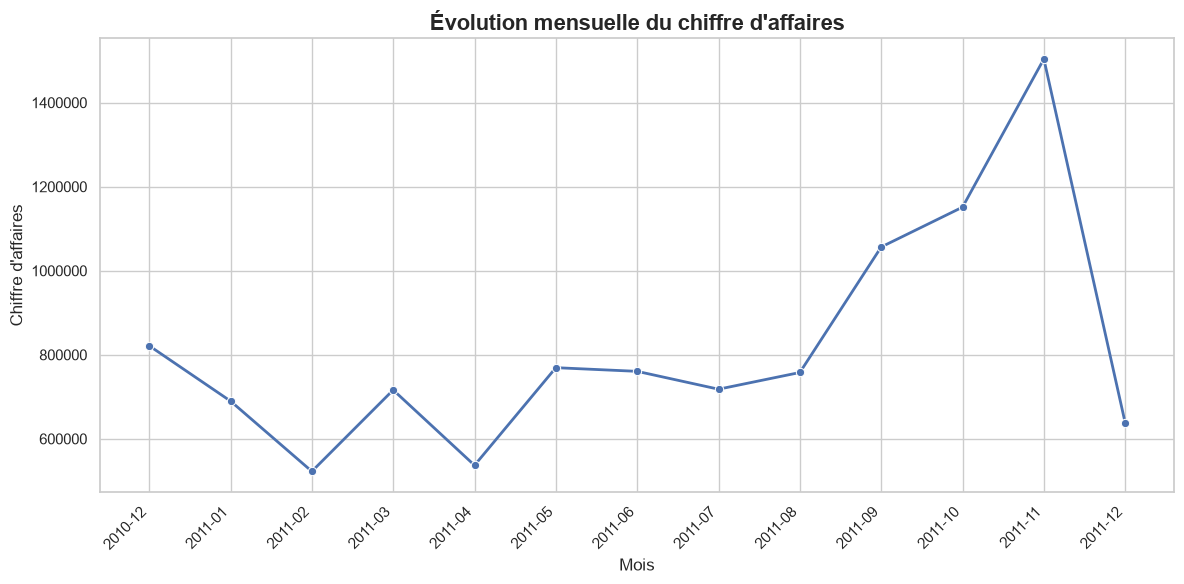

In [13]:

# 1. Calculer le chiffre d'affaires par mois
query_monthly = """
SELECT
    strftime('%Y-%m', InvoiceDate) AS mois,
    SUM(Quantity * UnitPrice) AS chiffre_affaires
FROM sales
WHERE Quantity > 0
  AND UnitPrice > 0
  AND InvoiceNo NOT LIKE 'C%'
GROUP BY strftime('%Y-%m', InvoiceDate)
ORDER BY mois;
"""

monthly = pd.read_sql_query(query_monthly, conn)

# 2. Créer le graphique
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly,
    x="mois",
    y="chiffre_affaires",
    marker="o",
    linewidth=2
)

plt.title(
    "Évolution mensuelle du chiffre d'affaires",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Mois", fontsize=12)
plt.ylabel("Chiffre d'affaires", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()


Cette courbe permet d'identifier les périodes de croissance et de baisse des ventes. Les mois présentant les chiffres d'affaires les plus élevés peuvent aider l'entreprise à mieux planifier ses stocks et ses campagnes commerciales.

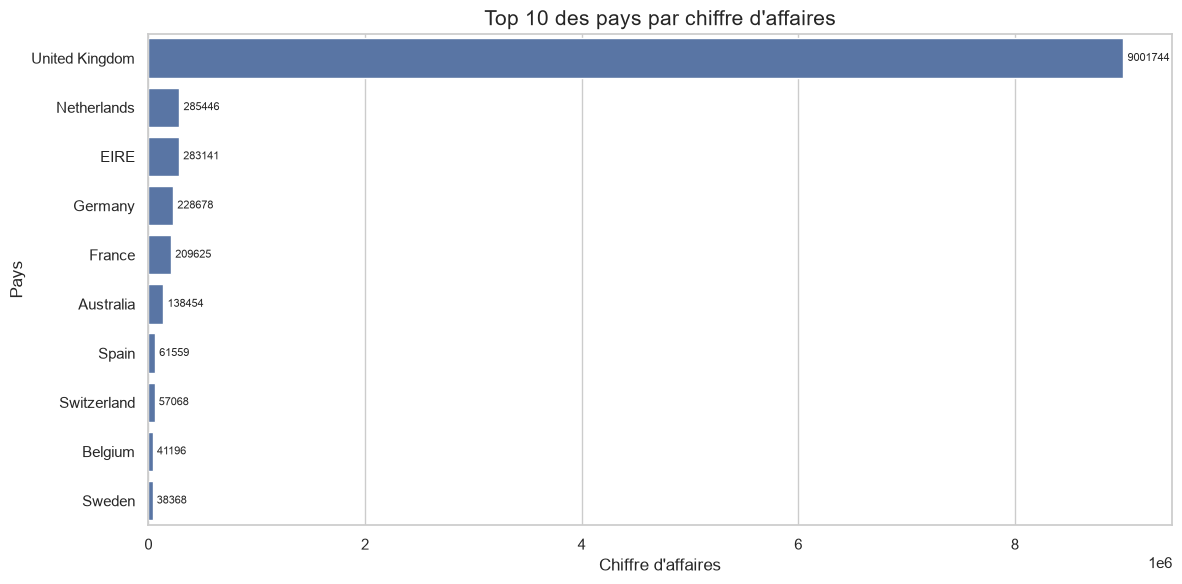

In [14]:

query_countries = """
SELECT
    Country AS pays,
    ROUND(SUM(Quantity * UnitPrice), 2) AS chiffre_affaires
FROM sales
WHERE Quantity > 0
  AND UnitPrice > 0
  AND InvoiceNo NOT LIKE 'C%'
GROUP BY Country
ORDER BY chiffre_affaires DESC
LIMIT 10;
"""

countries = pd.read_sql_query(query_countries, conn)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=countries,
    x="chiffre_affaires",
    y="pays"
)

plt.title("Top 10 des pays par chiffre d'affaires", fontsize=15)
plt.xlabel("Chiffre d'affaires")
plt.ylabel("Pays")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=8)

plt.tight_layout()
plt.show()


Ce classement identifie les principaux marchés de l'entreprise. Il permet de prioriser les efforts commerciaux et d'etudier les opportunités de développement dans les pays moins performants.

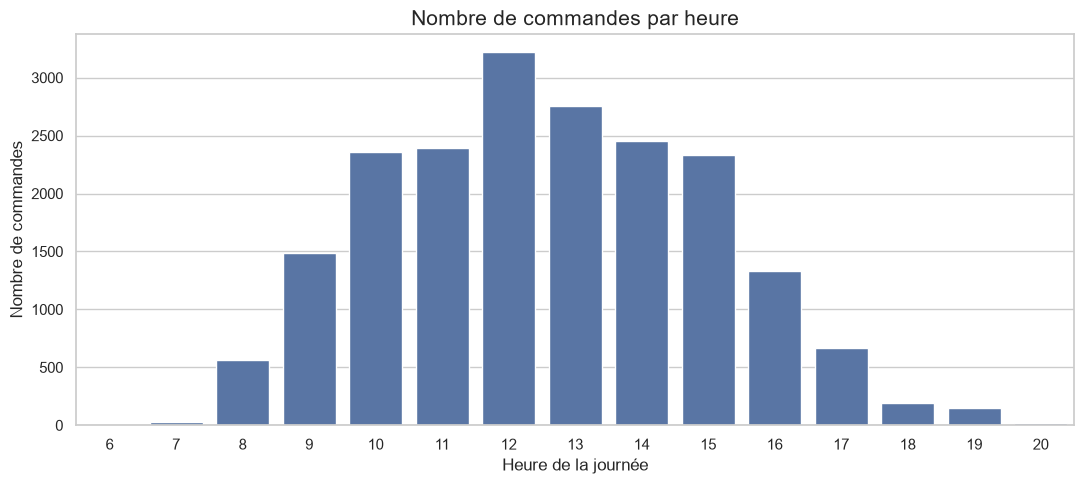

In [15]:

query_hours = """
SELECT
    CAST(strftime('%H', InvoiceDate) AS INTEGER) AS heure,
    COUNT(DISTINCT InvoiceNo) AS nombre_commandes
FROM sales
WHERE Quantity > 0
  AND UnitPrice > 0
  AND InvoiceNo NOT LIKE 'C%'
GROUP BY strftime('%H', InvoiceDate)
ORDER BY heure;
"""

hours = pd.read_sql_query(query_hours, conn)

plt.figure(figsize=(11, 5))
ax = sns.barplot(
    data=hours,
    x="heure",
    y="nombre_commandes"
)

plt.title("Nombre de commandes par heure", fontsize=15)
plt.xlabel("Heure de la journée")
plt.ylabel("Nombre de commandes")
plt.tight_layout()
plt.show()


Les heures qui concentrent le plus de commandes correspondent aux périodes de forte activité. Ces informations peuvent contribuer à optimiser le service client, la préparation des commandes et l'organisation des équipes.

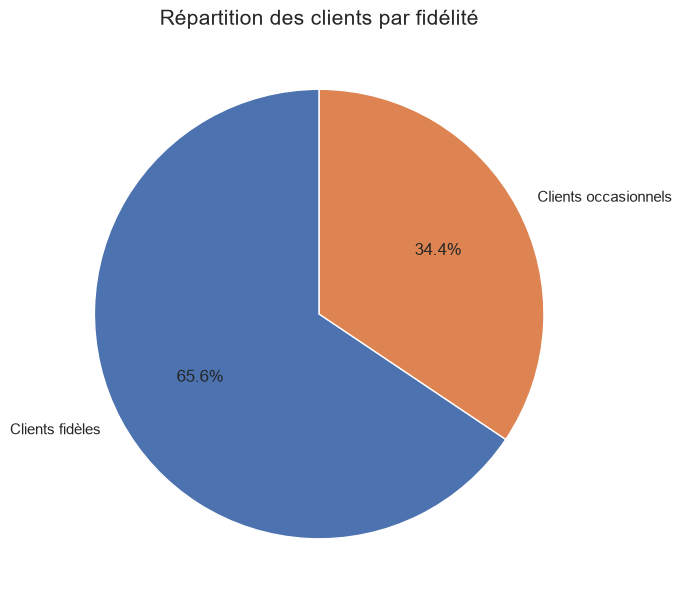

In [16]:

query_customers = """
WITH commandes_clients AS (
    SELECT
        CustomerID,
        COUNT(DISTINCT InvoiceNo) AS nb_commandes
    FROM sales
    WHERE CustomerID IS NOT NULL
      AND Quantity > 0
      AND UnitPrice > 0
      AND InvoiceNo NOT LIKE 'C%'
    GROUP BY CustomerID
)
SELECT
    CASE
        WHEN nb_commandes >= 2 THEN 'Clients fidèles'
        ELSE 'Clients occasionnels'
    END AS segment,
    COUNT(*) AS nombre_clients
FROM commandes_clients
GROUP BY segment;
"""

customers = pd.read_sql_query(query_customers, conn)

plt.figure(figsize=(7, 7))
plt.pie(
    customers["nombre_clients"],
    labels=customers["segment"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Répartition des clients par fidélité", fontsize=15)
plt.tight_layout()
plt.show()


Cette répartition mesure la part des clients ayant effectué plusieurs achats. Une proposition importante de clients occasionnels peut encourager l'entreprise à mettre en place des programmes de fidélisation. 

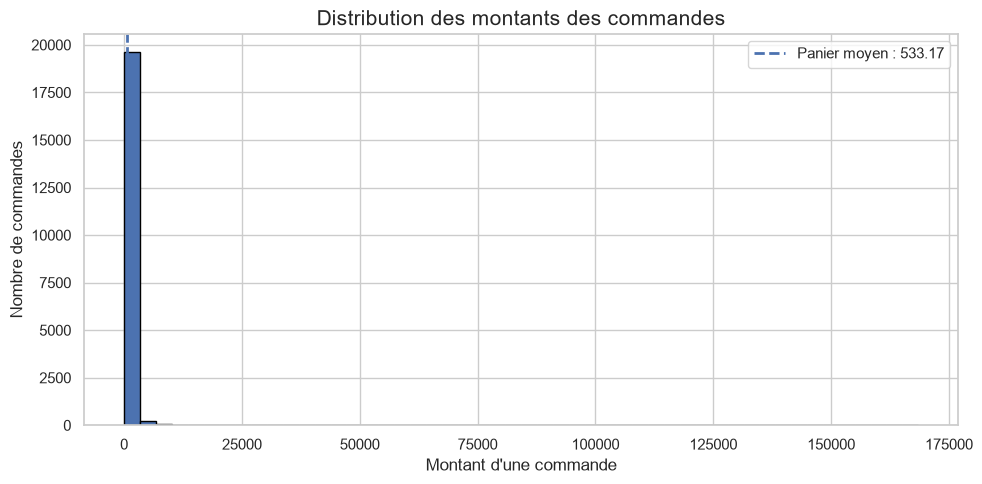

Panier moyen : 533.17
Nombre de commandes analysées : 19960


In [17]:

query_baskets = """
SELECT
    InvoiceNo,
    SUM(Quantity * UnitPrice) AS montant_commande
FROM sales
WHERE Quantity > 0
  AND UnitPrice > 0
  AND InvoiceNo NOT LIKE 'C%'
GROUP BY InvoiceNo;
"""

baskets = pd.read_sql_query(query_baskets, conn)

panier_moyen = baskets["montant_commande"].mean()

plt.figure(figsize=(10, 5))
plt.hist(
    baskets["montant_commande"],
    bins=50,
    edgecolor="black"
)

plt.axvline(
    panier_moyen,
    linestyle="--",
    linewidth=2,
    label=f"Panier moyen : {panier_moyen:.2f}"
)

plt.title("Distribution des montants des commandes", fontsize=15)
plt.xlabel("Montant d'une commande")
plt.ylabel("Nombre de commandes")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Panier moyen : {panier_moyen:.2f}")
print(f"Nombre de commandes analysées : {len(baskets)}")


L'histogramme montre comment les montants des commandes sont répartis. Si la distribution est concentré sur les petits montants avec quelques commandes très élevées, l'entreprise peut chercher à augmenter le panier moyen grâce aux ventes croisées ou offres groupées. 

In [18]:
conn.close()